# Marketing mix modeling: from raw spend to a budget decision

**The question.** A brand spends roughly €55k a week across TV, search, social and display. Which channels actually drive revenue, how close is each one to saturation, and how should the same budget be split?

The data here is synthetic, generated with known channel effects. That makes it possible to do something real projects can't: check the model's answers against the truth, and see exactly where and why it goes wrong.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mmm.data import make_dataset
from mmm.model import MarketingMixModel
from mmm.transforms import geometric_adstock, hill

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
COLORS = {"baseline": "#C9CED6", "tv": "#3B5BDB", "search": "#2F9E44", "social": "#E8590C", "display": "#9C36B5"}

ds = make_dataset()
df = ds.df
channels = ds.channels
df.head()

,week,promo,tv,search,social,display,revenue
0,2023-01-02,0.0,1555.08,15254.16,3308.81,6466.91,236715.20
1,2023-01-09,0.0,66530.32,7019.27,3865.48,6814.38,265149.44
2,2023-01-16,0.0,55159.91,8595.68,16898.43,3158.41,285954.03
3,2023-01-23,0.0,66457.69,13289.54,19351.74,14473.39,310115.88
4,2023-01-30,0.0,43155.27,17906.89,4874.67,7583.46,304793.28


## 1. Look at the data first

Four years of weekly data: revenue, spend per channel, and a promo flag. Before modeling, two things matter: how spend moves over time, and how much the channels move *together*. If two channels always rise and fall at the same time, no model can tell their effects apart.

Here the channels are planned fairly independently (low correlation), which is the good case.

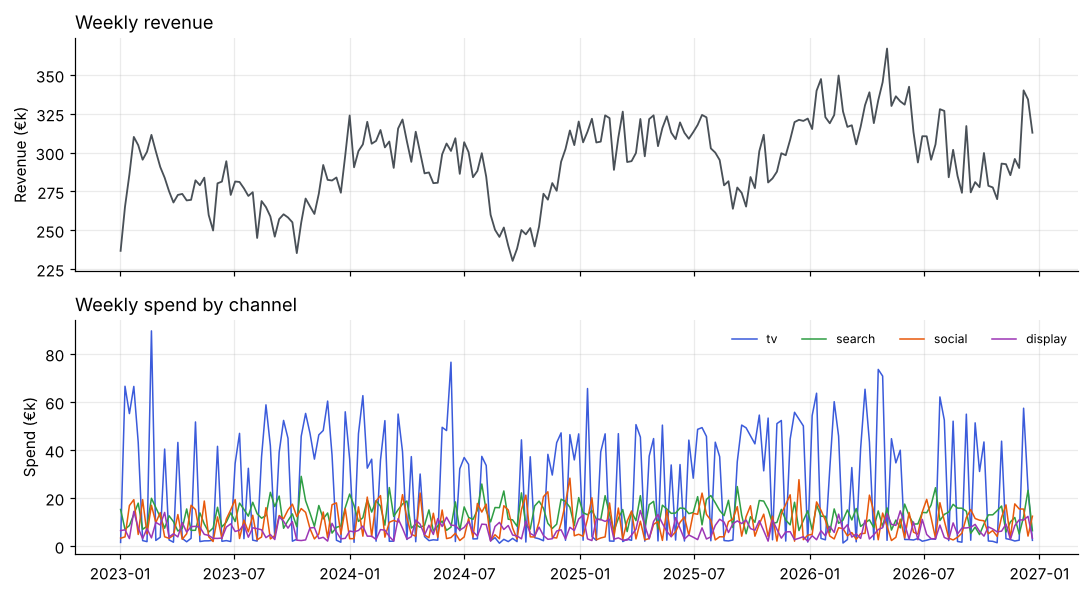

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
axes[0].plot(df["week"], df["revenue"] / 1000, color="#495057", lw=1.2)
axes[0].set_ylabel("Revenue (€k)")
axes[0].set_title("Weekly revenue", loc="left")
for c in channels:
    axes[1].plot(df["week"], df[c] / 1000, color=COLORS[c], lw=1, label=c)
axes[1].set_ylabel("Spend (€k)")
axes[1].set_title("Weekly spend by channel", loc="left")
axes[1].legend(frameon=False, ncol=4, fontsize=8)
fig.tight_layout()

In [3]:
summary = pd.DataFrame({
    "avg weekly spend": df[channels].mean().round(0),
    "share of spend": (df[channels].sum() / df[channels].sum().sum()).round(3),
    "corr. with other spend": [df[c].corr(df[[o for o in channels if o != c]].sum(axis=1)).round(2) for c in channels],
})
summary

,avg weekly spend,share of spend,corr. with other spend
tv,25802.0,0.468,0.10
search,12993.0,0.235,0.04
social,9684.0,0.176,0.06
display,6692.0,0.121,0.02


Display is the smallest channel, around 12% of spend, and its weekly swings are small in euro terms. Keep that in mind: a small channel's effect is easily lost in the week-to-week noise of a €250k+ revenue line.

## 2. Two effects every channel has

**Adstock.** An ad seen this week still works next week. Geometric adstock spreads each week's spend over the following weeks with a decay rate.

**Saturation.** The first €10k in a channel buys more than the next €10k. A Hill curve captures diminishing returns.

The model applies adstock first, then saturation, the same order Meridian uses by default.

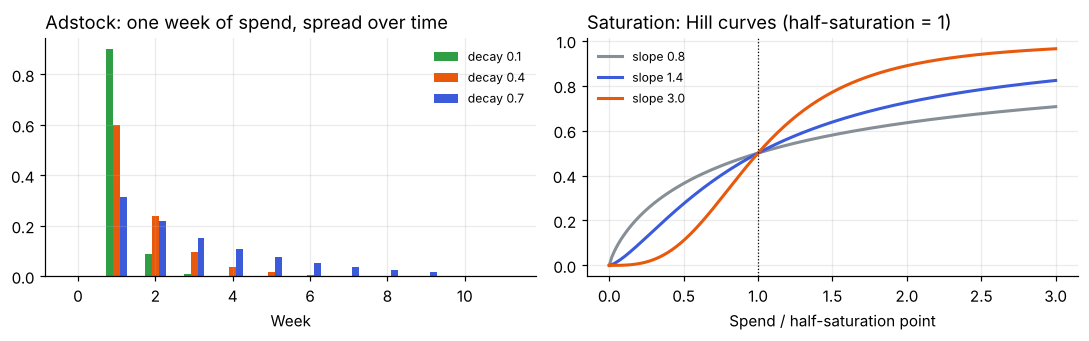

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
pulse = np.zeros(12)
pulse[1] = 1.0
for decay, col in [(0.1, "#2F9E44"), (0.4, "#E8590C"), (0.7, "#3B5BDB")]:
    axes[0].bar(np.arange(12) + (decay - 0.4) * 0.6, geometric_adstock(pulse, decay), width=0.18, color=col, label=f"decay {decay}")
axes[0].set_title("Adstock: one week of spend, spread over time", loc="left")
axes[0].set_xlabel("Week")
axes[0].legend(frameon=False, fontsize=8)
x = np.linspace(0, 3, 200)
for slope, col in [(0.8, "#868E96"), (1.4, "#3B5BDB"), (3.0, "#E8590C")]:
    axes[1].plot(x, hill(x, 1.0, slope), color=col, lw=2, label=f"slope {slope}")
axes[1].axvline(1, ls=":", color="black", lw=0.8)
axes[1].set_title("Saturation: Hill curves (half-saturation = 1)", loc="left")
axes[1].set_xlabel("Spend / half-saturation point")
axes[1].legend(frameon=False, fontsize=8)
fig.tight_layout()

## 3. Fit the model

Revenue = baseline (intercept, trend, yearly seasonality) + promo effect + the sum of channel responses + noise.

Four nonlinear parameters per channel are estimated by penalized least squares. The penalties play the role of weak priors: without them, a channel can look equally good as "small and unsaturated" or "large and heavily saturated". For each guess of the media parameters, the baseline coefficients are solved exactly, so the optimizer only searches the 16 nonlinear parameters.

In-sample R²: 0.981


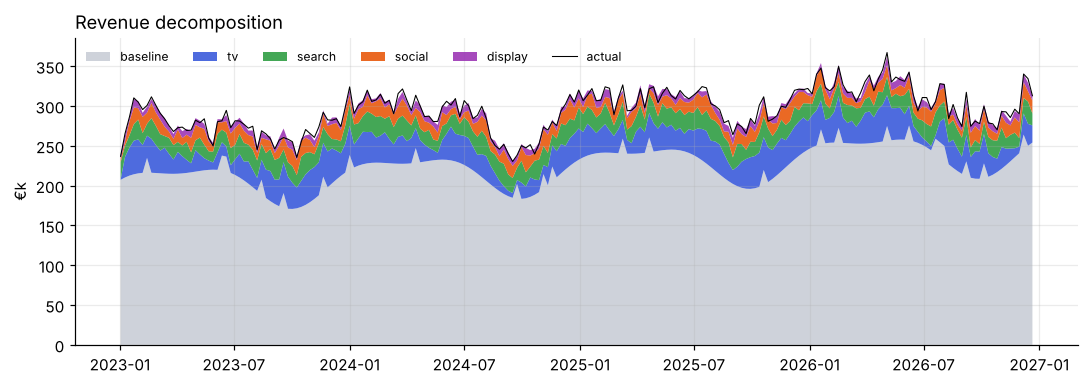

In [5]:
model = MarketingMixModel(channels).fit(df)
contrib = model.contributions(df)
print(f"In-sample R²: {model.r2(df):.3f}")

fig, ax = plt.subplots(figsize=(10, 3.6))
cols = ["baseline"] + channels
ax.stackplot(df["week"], *[contrib[c] / 1000 for c in cols], labels=cols, colors=[COLORS[c] for c in cols], alpha=0.9)
ax.plot(df["week"], df["revenue"] / 1000, color="black", lw=0.7, label="actual")
ax.set_ylabel("€k")
ax.set_title("Revenue decomposition", loc="left")
ax.legend(frameon=False, ncol=6, fontsize=8, loc="upper left")
fig.tight_layout()

## 4. Does it predict weeks it hasn't seen?

A good in-sample fit says little; a flexible model can fit noise. So the last 26 weeks are held out: the model is fitted on the first 182 weeks only and then asked to predict the final half year.

MAPE on training weeks: 0.97%
MAPE on held-out weeks: 1.07%


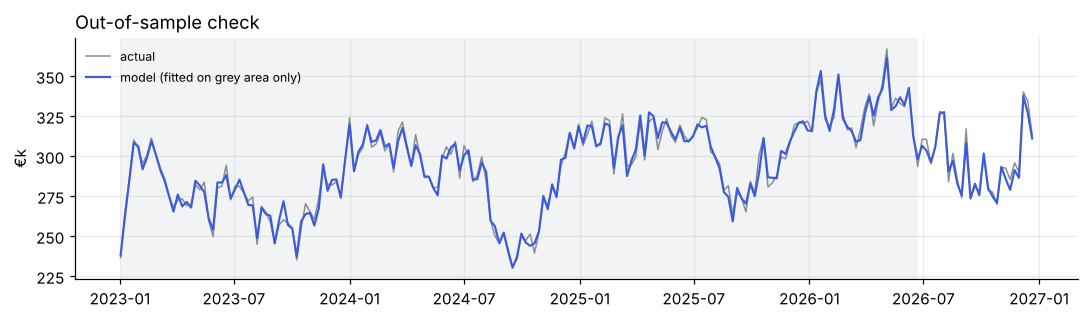

In [6]:
holdout = np.arange(len(df)) >= len(df) - 26
m_train = MarketingMixModel(channels).fit(df, train_mask=~holdout)
pred = m_train.predict(df)
y = df["revenue"].to_numpy()
mape_train = np.mean(np.abs(y[~holdout] - pred[~holdout]) / y[~holdout])
mape_test = np.mean(np.abs(y[holdout] - pred[holdout]) / y[holdout])
print(f"MAPE on training weeks: {mape_train:.2%}")
print(f"MAPE on held-out weeks: {mape_test:.2%}")

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(df["week"], y / 1000, color="#868E96", lw=1, label="actual")
ax.plot(df["week"], pred / 1000, color="#3B5BDB", lw=1.4, label="model (fitted on grey area only)")
ax.axvspan(df["week"].iloc[0], df["week"][~holdout].iloc[-1], color="#E9ECEF", alpha=0.6, lw=0)
ax.set_ylabel("€k")
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_title("Out-of-sample check", loc="left")
fig.tight_layout()

The error on unseen weeks is about the same as on training weeks, so the model is not overfitting.

## 5. The real test: are the channel ROIs right?

Predicting revenue well doesn't mean attributing it correctly. Here the truth is known, so we can check directly. Intervals come from a block bootstrap: resample residuals in 8-week blocks, refit, repeat.

In [7]:
boot = model.bootstrap_roi(df, n_boot=30)
roi = pd.concat([ds.true_roi(), model.roi(df), boot[["p05", "p95"]]], axis=1)
roi["truth in interval"] = (roi["true_roi"] >= roi["p05"]) & (roi["true_roi"] <= roi["p95"])
roi.round(2)

,true_roi,estimated_roi,p05,p95,truth in interval
tv,0.96,1.12,0.95,1.20,True
search,1.75,1.56,1.14,1.95,True
social,1.43,1.46,1.06,1.72,True
display,0.73,1.05,0.97,1.58,False


TV, search and social are close, with the truth inside the interval. **Display is not.** The model gives it an ROI of about 1.05 when the true value is 0.73, and the interval doesn't even include the truth.

This is the classic MMM failure. Display's contribution is a few thousand euros a week on top of a revenue line that moves by tens of thousands, so the data alone can't pin down how much of it belongs to display and how much to the baseline. A better optimizer won't fix that. What fixes it is outside information, typically an experiment.

## 6. Calibrating with a lift test

Suppose the team runs a geo holdout test on display: display is switched off in a set of regions for six weeks and sales are compared with matched regions (the method in the `campaign-causal-impact` repo). The test measures display's ROI with some uncertainty:

In [8]:
rng = np.random.default_rng(5)
true_display = ds.true_roi()["display"]
lift_se = 0.12
lift_measured = true_display + rng.normal(0, lift_se)
print(f"Lift test result for display: ROI {lift_measured:.2f} ± {lift_se:.2f}")

Lift test result for display: ROI 0.63 ± 0.12


The model takes this as one extra term in the objective: the further its display ROI is from the experiment, the larger the penalty, scaled by the experiment's standard error. A precise experiment pulls hard; a noisy one barely moves the model.

In [9]:
calibrated = MarketingMixModel(channels).fit(df, lift_tests={"display": (lift_measured, lift_se)})
comparison = pd.DataFrame({
    "true": ds.true_roi(),
    "uncalibrated": model.roi(df),
    "calibrated": calibrated.roi(df),
})
comparison["error before"] = (comparison["uncalibrated"] - comparison["true"]).abs()
comparison["error after"] = (comparison["calibrated"] - comparison["true"]).abs()
comparison.round(2)

,true,uncalibrated,calibrated,error before,error after
tv,0.96,1.12,1.13,0.16,0.17
search,1.75,1.56,1.56,0.19,0.19
social,1.43,1.46,1.44,0.04,0.02
display,0.73,1.05,0.63,0.32,0.09


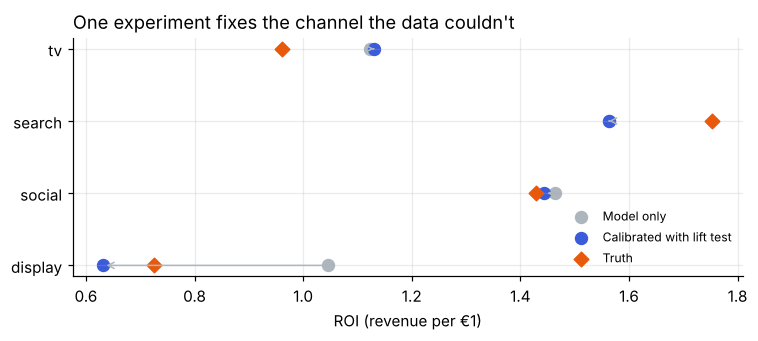

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ypos = np.arange(len(channels))
ax.scatter(comparison["uncalibrated"], ypos, color="#ADB5BD", s=60, label="Model only")
ax.scatter(comparison["calibrated"], ypos, color="#3B5BDB", s=60, label="Calibrated with lift test")
ax.scatter(comparison["true"], ypos, marker="D", color="#E8590C", s=45, label="Truth", zorder=3)
for i, c in enumerate(channels):
    ax.annotate("", xy=(comparison.loc[c, "calibrated"], i), xytext=(comparison.loc[c, "uncalibrated"], i),
                arrowprops=dict(arrowstyle="->", color="#ADB5BD"))
ax.set_yticks(ypos, channels)
ax.invert_yaxis()
ax.set_xlabel("ROI (revenue per €1)")
ax.set_title("One experiment fixes the channel the data couldn't", loc="left")
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()

Display moves to where the experiment put it, and its error drops from about 0.32 to 0.09. The other channels barely change: the revenue display was wrongly credited with goes back to the baseline, not to other media. (The experiment itself is noisy, which is why display lands at 0.63 rather than exactly 0.73.)

## 7. Where is each channel on its curve?

Average ROI answers "was this channel worth it?". For budget decisions the better question is **marginal ROI**: what does the *next* euro return at today's spend level?

In [11]:
def marginal_roi(m, channel, spend, step=100.0):
    s = np.array([spend, spend + step])
    r = m.response_curve(channel, s)
    return (r[1] - r[0]) / step

current = {c: float(df[c].mean()) for c in channels}
mroi = pd.DataFrame({
    "current weekly spend": pd.Series(current).round(0),
    "average ROI": calibrated.roi(df).round(2),
    "marginal ROI": pd.Series({c: marginal_roi(calibrated, c, current[c]) for c in channels}).round(2),
})
mroi

,current weekly spend,average ROI,marginal ROI
tv,25802.0,1.13,0.86
search,12993.0,1.56,1.05
social,9684.0,1.44,1.09
display,6692.0,0.63,0.80


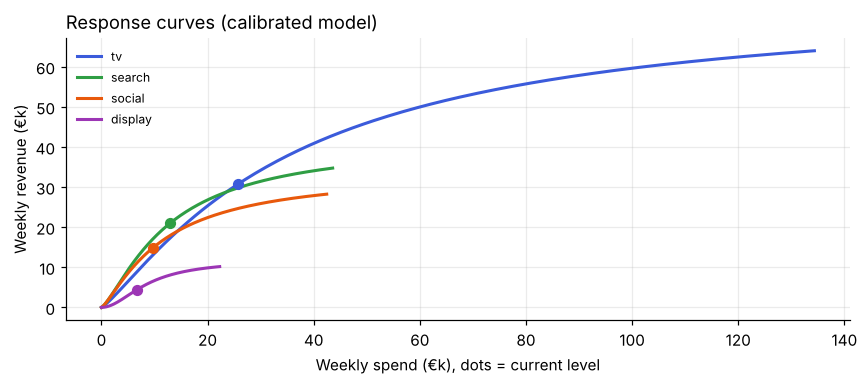

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for c in channels:
    grid = np.linspace(0, df[c].max() * 1.5, 200)
    ax.plot(grid / 1000, calibrated.response_curve(c, grid) / 1000, color=COLORS[c], lw=2, label=c)
    ax.scatter(current[c] / 1000, calibrated.response_curve(c, np.array([current[c]]))[0] / 1000, color=COLORS[c], s=40, zorder=3)
ax.set_xlabel("Weekly spend (€k), dots = current level")
ax.set_ylabel("Weekly revenue (€k)")
ax.set_title("Response curves (calibrated model)", loc="left")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()

Search and social still return more than €1 for the next euro. TV and display are past the point where an extra euro pays for itself. That points to the reallocation.

## 8. Same budget, better split

The optimizer keeps total weekly spend fixed and lets each channel move at most ±50% from today, so recommendations stay within the range the model has actually observed.

Display hits the −50% limit. The model would cut it further, but that would be extrapolating outside observed spend levels, which is exactly where the next experiment should go.

In [13]:
plan = calibrated.optimize_budget(sum(current.values()), current, max_change=0.5)
plan["change"] = (plan["optimized_spend"] / plan["current_spend"] - 1).map("{:+.0%}".format)
uplift = plan["optimized_revenue"].sum() - plan["current_revenue"].sum()
print(f"Media-driven revenue: €{plan['current_revenue'].sum():,.0f} → €{plan['optimized_revenue'].sum():,.0f} per week "
      f"({uplift / plan['current_revenue'].sum():+.1%}, about €{uplift * 52 / 1000:,.0f}k a year at the same spend)")
plan

Media-driven revenue: €71,109 → €71,672 per week (+0.8%, about €29k a year at the same spend)


,current_spend,optimized_spend,current_revenue,optimized_revenue,change
tv,25802.0,24666.0,30800.0,29801.0,-4%
search,12993.0,15184.0,21053.0,23186.0,+17%
social,9684.0,11975.0,14842.0,17108.0,+24%
display,6692.0,3346.0,4414.0,1577.0,-50%


## 9. What I'd do differently with real data

- **Fit the Bayesian version.** `meridian/fit_meridian.py` fits the same data with Google Meridian, which gives full posterior distributions instead of a point estimate plus bootstrap, and supports ROI priors directly.
- **Go geo-level.** Regional data multiplies the number of observations and lets the model use variation across regions, not just over time. It is the single biggest improvement for identification.
- **Make experiments a habit.** Calibration only fixed display because someone ran a test. A rolling plan of geo tests, starting with the channels where the model is least certain, keeps the MMM honest.
- **Treat the optimizer as a starting point.** Recommendations outside the observed spend range are extrapolation. Move budget in steps and measure.